# 🧪 Lekcja 8: Inżynieria Cech (*Feature Engineering*) — jak wycisnąć „ukryte złoto” z istniejących kolumn?

W poprzedniej lekcji nasz uczciwy sędzia (**5-Fold Cross-Validation**) pokazał, że po usunięciu 2 anomalii średni błąd naszego modelu na 12 cechach wynosi **`17 324 $`**.

Dziś poznasz umiejętność, która odróżnia zwykłego programistę od prawdziwego eksperta Data Science: **Inżynierię Cech (*Feature Engineering*)**, czyli tworzenie **zupełnie nowych, mądrzejszych kolumn** na podstawie tych, które już mamy w tabeli!

---

### 🤔 Zaraz, zaraz — skoro komputer ma już w tabeli parter, piętro i piwnicę, to po co mamy je dla niego dodawać?!

To jedno z najważniejszych pytań w Machine Learningu!  
Wyobraź sobie, że oglądasz dom, a pośrednik mówi Ci: *„Piwnica ma 1000 stóp, parter ma 1000 stóp, a piętro ma 800 stóp”*.  
Twój ludzki mózg w ułamku sekundy dodaje te trzy liczby i myśli: **„Aha, ten budynek ma łącznie 2800 stóp kwadratowych powierzchni!”**.

**A jak myśli Drzewo Decyzyjne w naszym Lesie Losowym?**  
Pamiętasz z Lekcji 4, że drzewo zadaje pytania typu: *„Czy kolumna X jest większa niż liczba Y?”*.
* Drzewo potrafi w jednym kroku spojrzeć **tylko na JEDNĄ kolumnę naraz** (np. *„Czy parter > 1000?”*, a piętro niżej *„Czy piwnica > 1000?”*).
* **Drzewo decyzyjne NIE POTRAFI samo z siebie dodać ani odjąć od siebie dwóch kolumn!** Dopóki sami nie podamy mu na tacy nowej kolumny z sumą, drzewo widzi tylko porozrzucane puzzle zamiast całego obrazka.

---

### 🛠️ Jakie 4 nowe cechy stworzymy dziś z pomocą `../data/data_description.txt`?

| Nowa cecha | Z jakich kolumn ją budujemy? (Wzór matematyczny) | Dlaczego to pomaga modelowi (logika rzeczoznawcy)? |
| :--- | :--- | :--- |
| **1. `TotalSF`** *(Całkowita powierzchnia budynku)* | `TotalBsmtSF + 1stFlrSF + 2ndFlrSF`<br>*(Piwnica + Parter + Piętro)* | Zamiast patrzeć osobno na piwnicę i piętra, model jednym rzutem oka widzi **łączny gabaryt całego budynku**! |
| **2. `TotalBath`** *(Łączna liczba łazienek)* | `FullBath + (0.5 * HalfBath) + BsmtFullBath + (0.5 * BsmtHalfBath)` | W oryginalnej tabeli łazienki są rozsypane aż w **4 kolumnach**! Łączymy je w jeden wskaźnik, gdzie pełna łazienka (z wanną/prysznicem) liczy się jako **`1.0`**, a mała toaleta (`HalfBath` — samo WC z umywalką) jako **`0.5`**! |
| **3. `HouseAge`** *(Wiek domu w chwili sprzedaży)* | `YrSold - YearBuilt`<br>*(Rok sprzedaży minus Rok budowy)* | Kupującego interesuje, **ile lat miał dom w dniu zakupu** (np. 0 lat = prosto od dewelopera, 80 lat = stary dom). |
| **4. `RemodAge`** *(Lata od ostatniego remontu)* | `YrSold - YearRemodAdd`<br>*(Rok sprzedaży minus Rok remontu)* | Nawet 70-letni dom zachowuje wysoką cenę, jeśli rok przed sprzedażą (`RemodAge = 1`) przeszedł generalny remont! |

--- Siła związku z ceną SalePrice (Korelacja od -1.0 do +1.0) ---
GrLivArea      0.735
TotalBsmtSF    0.651
TotalSF        0.833
FullBath       0.562
TotalBath      0.636
HouseAge      -0.524
RemodAge      -0.510
dtype: float64


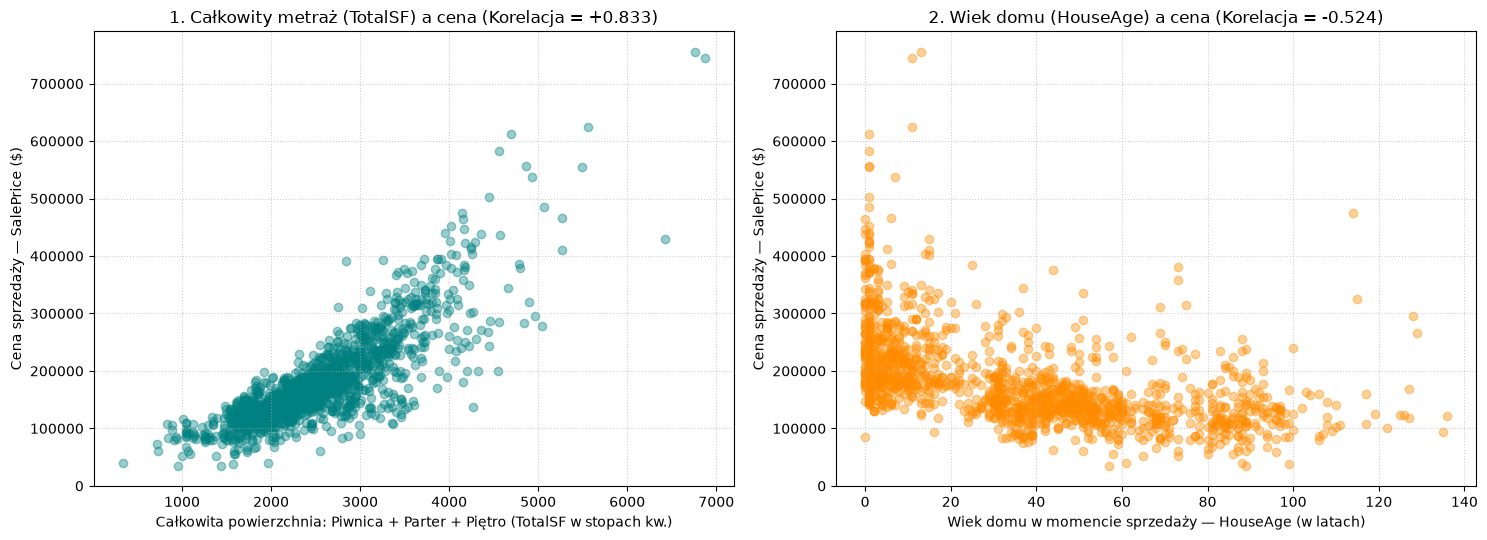

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Wczytujemy dane z folderu ../data/ i usuwamy 2 słynne anomalie (tak jak na końcu Lekcji 7)
train = pd.read_csv('../data/train.csv')
train = train[~((train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000))].copy()

# 2. Tworzymy nasze 4 NOWE CECHY (Feature Engineering!)
train['TotalSF'] = train['TotalBsmtSF'] + train['1stFlrSF'] + train['2ndFlrSF']
train['TotalBath'] = train['FullBath'] + (0.5 * train['HalfBath']) + train['BsmtFullBath'] + (0.5 * train['BsmtHalfBath'])
train['HouseAge'] = train['YrSold'] - train['YearBuilt']
train['RemodAge'] = train['YrSold'] - train['YearRemodAdd']

# 3. Sprawdzamy matematyczną siłę związku z ceną (współczynnik korelacji .corr())
badane_kolumny = ['GrLivArea', 'TotalBsmtSF', 'TotalSF', 'FullBath', 'TotalBath', 'HouseAge', 'RemodAge']
korelacje = train[badane_kolumny].corrwith(train['SalePrice']).round(3)
print('--- Siła związku z ceną SalePrice (Korelacja od -1.0 do +1.0) ---')
print(korelacje)

# 4. WIZUALIZACJA: Zobaczmy nasze nowe cechy na dwóch wykresach obok siebie!
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Wykres lewy: Całkowita powierzchnia (TotalSF) vs Cena domu (SalePrice)
ax1.scatter(train['TotalSF'], train['SalePrice'], alpha=0.4, color='teal')
ax1.set_title(f"1. Całkowity metraż (TotalSF) a cena (Korelacja = +{korelacje['TotalSF']})")
ax1.set_xlabel('Całkowita powierzchnia: Piwnica + Parter + Piętro (TotalSF w stopach kw.)')
ax1.set_ylabel('Cena sprzedaży — SalePrice ($)')
ax1.grid(True, linestyle=':', alpha=0.6)

# Wykres prawy: Wiek domu w chwili sprzedaży (HouseAge) vs Cena domu (SalePrice)
ax2.scatter(train['HouseAge'], train['SalePrice'], alpha=0.4, color='darkorange')
ax2.set_title(f"2. Wiek domu (HouseAge) a cena (Korelacja = {korelacje['HouseAge']})")
ax2.set_xlabel('Wiek domu w momencie sprzedaży — HouseAge (w latach)')
ax2.set_ylabel('Cena sprzedaży — SalePrice ($)')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 🔬 Matematyka pod maską: Co oznaczają liczby korelacji (`+0.833` oraz `-0.524`)?

W powyższym kodzie użyliśmy metody `.corrwith(train['SalePrice'])`, która oblicza tzw. **współczynnik korelacji liniowej Pearsona** (w skrócie **korelację**). To jeden z najlepszych kompasów każdego Data Scientista!

#### 1. Jak czytać współczynnik korelacji? (Miarka od `-1.0` do `+1.0`)
Korelacja to zawsze liczba z przedziału **od `-1.0` do `+1.0`**, która mówi, **jak mocno i w którą stronę** dwie cechy idą ze sobą w parze:

| Wartość korelacji | Jak wygląda wykres punktowy? | Co to oznacza po ludzku? | Przykład z naszych obliczeń powyżej |
| :--- | :--- | :--- | :--- |
| **Blisko `+1.0`** *(np. od `+0.7` do `+1.0`)* | Kropki pną się stromo **w górę** (↗️) | **Silna korelacja DODATNIA:** Gdy pierwsza liczba rośnie, druga też mocno rośnie! | Nasza nowa cecha **`TotalSF` ma korelację aż `+0.833`**! Zauważ, że pobiła na głowę zarówno sam metraż nad ziemią (`GrLivArea = +0.735`), jak i samą piwnicę (`TotalBsmtSF = +0.651`)! Podobnie nowe **`TotalBath` (`+0.636`)** pobiło stare `FullBath` (`+0.562`). |
| **Okolice `0.0`** *(np. od `-0.1` do `+0.1`)* | Bezładna chmura kropek (☁️) | **Brak związku:** Zmiana jednej liczby nie ma wpływu na drugą. | Np. miesiąc sprzedaży (`MoSold`) ma korelację ok. `+0.04` z ceną domu. |
| **Blisko `-1.0`** *(np. od `-0.5` do `-1.0`)* | Kropki opadają **w dół** (↘️) | **Silna korelacja UJEMNA:** Gdy pierwsza liczba **ROŚNIE**, druga **SPADA**! | Spójrz na prawy wykres i wynik dla **`HouseAge = -0.524`**! Dlaczego z przodu jest znak **minus**? Bo im **WIĘKSZY wiek domu** (idziemy w prawo na osi X: 20, 50, 100 lat), tym **NIŻSZA cena domu** (kropki zjeżdżają w dół na osi Y)! |

> 💡 **Ważna zasada:** W Machine Learningu korelacja ujemna (np. `-0.524`) jest **tak samo cenna** jak dodatnia (`+0.524`)! Znak `+` lub `-` mówi tylko o kierunku (czy cena rośnie, czy spada), natomiast o sile podpowiedzi dla modelu decyduje odległość od zera!

---

#### 2. Magia wektorów w `pandas`: Jak `train['TotalBsmtSF'] + train['1stFlrSF']` działa bez pętli `for`?
W zwykłym Pythonie, żeby dodać do siebie dwie listy po 1458 liczb, musiałbyś pisać pętlę `for`.  
W `pandas` i `numpy` działa tzw. **operacja wektorowa (*Vectorization*)**:
* Kiedy piszesz `train['YrSold'] - train['YearBuilt']`, komputer ustawia obie kolumny obok siebie jak dwa słupki w Excelu i **w jednym cyklu procesora odejmuje wiersz 1 od wiersza 1, wiersz 2 od wiersza 2... aż do wiersza 1458**!
* A gdy piszesz `0.5 * train['HalfBath']`, mnoży każdą kratkę w kolumnie przez `0.5`.

Średni błąd 5-Fold CV PRZED nowymi cechami (12 cech): 17,324 $
Średni błąd 5-Fold CV PO dodaniu nowych cech (16 cech): 16,960 $
🎉 Zyskaliśmy kolejne 364 $ dokładności i przebiliśmy barierę 17 000 $!


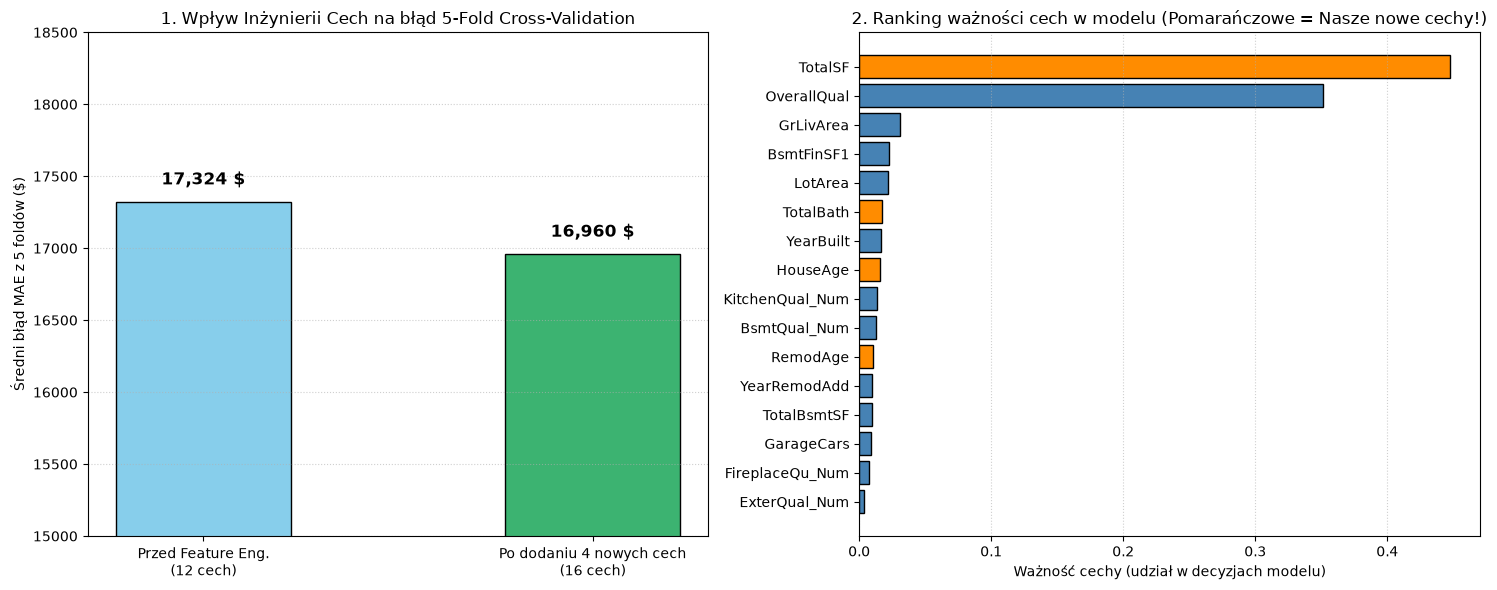

In [2]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor

# Kodujemy nasze 4 cechy porządkowe z Lekcji 6
mapa_jakosci = {'Brak': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
for kol in ['KitchenQual', 'ExterQual', 'BsmtQual', 'FireplaceQu']:
    train[kol + '_Num'] = train[kol].fillna('Brak').map(mapa_jakosci)

# Zestaw 1: Nasze 12 cech z końca Lekcji 7 (przed Inżynierią Cech)
cechy_stare = [
    'OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF',
    'YearBuilt', 'YearRemodAdd', 'LotArea', 'BsmtFinSF1',
    'KitchenQual_Num', 'ExterQual_Num', 'BsmtQual_Num', 'FireplaceQu_Num'
]

# Zestaw 2: Dodajemy nasze 4 nowe, autorskie cechy!
cechy_nowe = cechy_stare + ['TotalSF', 'TotalBath', 'HouseAge', 'RemodAge']

y = train['SalePrice']
kf = KFold(n_splits=5, shuffle=True, random_state=42)
model = RandomForestRegressor(n_estimators=100, random_state=42)

# Uczciwy pojedynek w 5-Fold Cross-Validation:
wynik_stary = -cross_val_score(model, train[cechy_stare], y, cv=kf, scoring='neg_mean_absolute_error').mean()
wynik_nowy = -cross_val_score(model, train[cechy_nowe], y, cv=kf, scoring='neg_mean_absolute_error').mean()

print(f'Średni błąd 5-Fold CV PRZED nowymi cechami (12 cech): {wynik_stary:,.0f} $')
print(f'Średni błąd 5-Fold CV PO dodaniu nowych cech (16 cech): {wynik_nowy:,.0f} $')
print(f'🎉 Zyskaliśmy kolejne {wynik_stary - wynik_nowy:,.0f} $ dokładności i przebiliśmy barierę 17 000 $!')

# Uczymy model na pełnym zestawie 16 cech, aby zajrzeć do jego mózgu (feature_importances_)
model.fit(train[cechy_nowe], y)
waznosc = pd.Series(model.feature_importances_, index=cechy_nowe).sort_values(ascending=True)

# WIZUALIZACJA: Po lewej spadek błędu 5-Fold CV, po prawej ranking ważności wszystkich 16 cech!
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Wykres lewy: Porównanie błędu 5-Fold CV
etapy = ['Przed Feature Eng.\n(12 cech)', 'Po dodaniu 4 nowych cech\n(16 cech)']
wartosci = [wynik_stary, wynik_nowy]
ax1.bar(etapy, wartosci, color=['skyblue', 'mediumseagreen'], edgecolor='black', width=0.45)
ax1.set_title('1. Wpływ Inżynierii Cech na błąd 5-Fold Cross-Validation')
ax1.set_ylabel('Średni błąd MAE z 5 foldów ($)')
ax1.set_ylim(15000, 18500)
for i, v in enumerate(wartosci):
    ax1.text(i, v + 120, f'{v:,.0f} $', ha='center', fontweight='bold', fontsize=12)
ax1.grid(axis='y', linestyle=':', alpha=0.6)

# Wykres prawy: Ranking ważności cech (nasze nowe cechy zaznaczamy na złoto/pomarańczowo!)
nowe_nazwy = ['TotalSF', 'TotalBath', 'HouseAge', 'RemodAge']
kolory_cech = ['darkorange' if nazwa in nowe_nazwy else 'steelblue' for nazwa in waznosc.index]
ax2.barh(waznosc.index, waznosc.values, color=kolory_cech, edgecolor='black')
ax2.set_title('2. Ranking ważności cech w modelu (Pomarańczowe = Nasze nowe cechy!)')
ax2.set_xlabel('Ważność cechy (udział w decyzjach modelu)')
ax2.grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 🏆 Spójrz na prawy wykres powyżej — co wydarzyło się w „mózgu” naszego modelu?

Na prawym wykresie (`plt.barh`, czyli *horizontal bar* — poziomy wykres słupkowy) zaznaczyliśmy na **pomarańczowo** nasze 4 własnoręcznie wymyślone cechy, a na **niebiesko** stare cechy z pliku CSV.

Zobacz, jaki spektakularny sukces odniosła nasza cecha **`TotalSF` (Całkowita powierzchnia budynku)**:
1. **Wskoczyła od razu na 1. miejsce w całym modelu (ponad 44% udziału we wszystkich decyzjach drzew!)**, wyprzedzając nawet słynną ocenę jakości `OverallQual` (`35%`)!
2. Dlaczego tak się stało? Bo wcześniej model musiał osobno pytać o `GrLivArea` i osobno o `TotalBsmtSF`. Kiedy podaliśmy mu na tacy `TotalSF = TotalBsmtSF + 1stFlrSF + 2ndFlrSF`, drzewa decyzyjne uznały tę jedną liczbę za swój główny drogowskaz przy wycenie nieruchomości, a nasz błąd 5-Fold CV spadł z **`17 324 $`** do **`16 960 $`**!

In [3]:
# 🎯 ĆWICZENIE: Zostań Inżynierem Cech! Stwórz i przetestuj własną cechę!
#
# Wybierz jeden z poniższych pomysłów (albo wymyśl własny na podstawie ../data/data_description.txt):
# • Pomysł A (Łączna powierzchnia tarasów i ganków — 'TotalPorchSF'):
#   train['TotalPorchSF'] = train['WoodDeckSF'] + train['OpenPorchSF'] + train['EnclosedPorch'] + train['3SsnPorch'] + train['ScreenPorch']
# • Pomysł B (Średnia wielkość pokoju nad ziemią — 'AvgRoomSize'):
#   train['AvgRoomSize'] = train['GrLivArea'] / train['TotRmsAbvGrd']
#
# 1. Stwórz w tabeli `train` nową kolumnę według wybranego wzoru.
# 2. Sprawdź jej korelację z ceną domu za pomocą: print(train['TwojaNowaKolumna'].corr(train['SalePrice']))

# Miejsce na Twój kod:


---
### 📌 Podsumowanie lekcji w 3 punktach

1. **Po co robimy *Feature Engineering*:** Pojedynczy krok drzewa decyzyjnego bada tylko jedną kolumnę naraz i nie potrafi sam z siebie dodawać ani odejmować kolumn — dlatego połączenie piwnicy, parteru i piętra w jedną cechę `TotalSF` tak bardzo ułatwia modelowi pracę.
2. **Współczynnik korelacji Pearsona (`.corr()` od `-1.0` do `+1.0`):** Mierzy siłę i kierunek związku liniowego z ceną. Dodatnia korelacja (`TotalSF = +0.833`, `TotalBath = +0.636`) oznacza, że wzrost cechy podnosi cenę, a ujemna (`HouseAge = -0.524`) oznacza, że wzrost wieku obniża cenę.
3. **Weryfikacja nowych cech:** Po dodaniu 4 autorskich cech (`TotalSF`, `TotalBath`, `HouseAge`, `RemodAge`) średni błąd 5-Fold CV spadł z `17 324 $` do `16 960 $`, a `TotalSF` zajęło 1. miejsce w rankingu ważności cech (`model.feature_importances_`).